In [1]:
import numpy as np
import pandas as pd
import torch
import h5py
import joblib
import os, sys
import subprocess
import matplotlib.pyplot as plt
import math, json

In [2]:
sys.path.insert(0, "/mnt/efsUCE/umap_pytorch")  #git+https://github.com/ucscBrainExplorer/umap_pytorch.git
import umap_pytorch
print(umap_pytorch.__file__)

/mnt/efsUCE/umap_pytorch/umap_pytorch/__init__.py


In [99]:
results_dir = "/mnt/efsUCE/Zhuang-ABCA-1-2_cxg_shuffled"

embedding_h5_file = "pca.h5"
embedding_h5_file_key = "pca"
knn_outfile = "knn_30_ivfflat.npz"
k = 10
batch_size= 2048 #1024 #512, #256, #64, # gpu memory related

existing_model_iteration = 30
epochs = 5

## Load Embedding back into memory

In [4]:
# Load the embedding data
# Open the HDF5 file
with h5py.File(os.path.join(results_dir, embedding_h5_file), "r") as f:
    X_data = f[embedding_h5_file_key][:]

# Convert to PyTorch tensor so to use gpu
data_tensor = torch.from_numpy(X_data)
data_tensor, data_tensor.shape

(tensor([[ 0.0426,  0.1306, -0.1678,  ..., -0.0734, -0.0106, -0.0041],
         [-0.0563, -0.0513, -0.0347,  ...,  0.0182,  0.0728,  0.0053],
         [-0.0275,  0.0673,  0.1057,  ...,  0.0412, -0.0490,  0.0122],
         ...,
         [ 0.2598, -0.0093,  0.0490,  ..., -0.0383,  0.0179, -0.0281],
         [ 0.3281, -0.1596, -0.0599,  ..., -0.0311, -0.0370, -0.0314],
         [ 0.0154,  0.1517, -0.1010,  ...,  0.0120, -0.1453,  0.1021]]),
 torch.Size([5788737, 50]))

## Load Knn Back

In [5]:
# load knn back
data = np.load(os.path.join(results_dir, knn_outfile))
knn_indices = data["indices"]
knn_distances = data["distances"]

In [6]:
knn_distances = np.sqrt(knn_distances)

## PUMAP 
using umap_pytorch https://github.com/ucscBrainExplorer/umap_pytorch.git

## set up training on all cells

In [7]:
knn_indices = knn_indices[:,:k]
knn_dists = knn_distances[:,:k]

### Load model back or start with a new model

In [100]:
if existing_model_iteration > 0:
    from umap_pytorch import load_pumap
    path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
    pumap = load_pumap(path)
    pumap.epochs = epochs
    print ("Start with existing model", f'pytorch_e{existing_model_iteration}.pkl')
else:
    import torch.nn.functional as F
    pumap = umap_pytorch.PUMAP(
        encoder=None,           # nn.Module, None for default
        decoder=None,           # nn.Module, True for default, None for encoder only
        n_neighbors=10,
        min_dist= 0.1,
        metric="euclidean",
        n_components=2,
        beta=1.0,               # How much to weigh reconstruction loss for decoder
        reconstruction_loss=F.binary_cross_entropy_with_logits, # pass in custom reconstruction loss functions
        random_state=None,
        lr=1e-3,
        epochs=epochs, #5,
        batch_size= batch_size,
        num_workers=0, #10,
        num_gpus=1,
        match_nonparametric_umap=False, # Train network to match embeddings from non parametric umap,
    )
    print ("Start with a new model")

Loading PUMAP object from pickled file.
Start with existing model pytorch_e30.pkl


### Train

In [101]:
existing_model_iteration, pumap.epochs

(30, 5)

In [102]:
np.product = np.prod  # alias to fix compatibility
pumap.fit(data_tensor, knn_indices, knn_dists)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Fitting parametric Umap
There are knn provided by the user
Start fuzzy_simplicial_set ...
End fuzzy_simplicial_set
Training start
Start UMAPDataset initiation ...
batch_size: 1024


/mnt/efsUCE/umap_pytorch/umap_pytorch/data.py:37: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, device="cuda")


End UMAPDataset. 7406156800 5788737


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type            | Params | Mode 
----------------------------------------------------
0 | encoder | default_encoder | 91.0 K | train
----------------------------------------------------
91.0 K    Trainable params
0         Non-trainable params
91.0 K    Total params
0.364     Total estimated model params size (MB)
10        Modules in train mode
0         Modules in eval mode


dataloader len: 5653


/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=5` reached.


### Saving model

In [103]:
existing_model_iteration = existing_model_iteration+ pumap.epochs
existing_model_iteration

35

In [104]:
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
pumap.save(model_path)

Pickled PUMAP object at /mnt/efsUCE/Zhuang-ABCA-1-2_cxg_shuffled/pytorch_e35.pkl


### Quick viz X_umap_pytorch

In [91]:
#existing_model_iteration =30

In [105]:
# load model
from umap_pytorch import load_pumap
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
pumap = load_pumap(model_path)
print("Loaded model", f'pytorch_e{existing_model_iteration}.pkl')

Loading PUMAP object from pickled file.
Loaded model pytorch_e35.pkl


#### random 200K

In [106]:
view_size = 200_000
if X_data.shape[0] < view_size:
    subset_indices = range (0, X_data.shape[0])
else:
    np.random.seed(42)  # set seed for reproducibility
    subset_indices = np.random.choice(X_data.shape[0], size= view_size, replace=False)

In [107]:
X_umap_pytorch = pumap.transform(data_tensor[subset_indices])

Reducing array of shape torch.Size([200000, 50]) to (200000, 2)


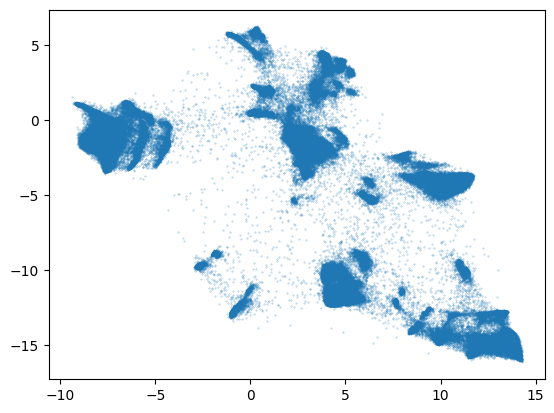

In [108]:
# current
plt.scatter(X_umap_pytorch[:,0], X_umap_pytorch[:,1], alpha =0.5, s=0.1)
plt.show()

## optional quick viz with metadata

In [33]:
metadata_file = "obs.tsv.gz"
metadata = pd.read_csv(os.path.join(results_dir, metadata_file), sep ='\t')

In [34]:
metadata.columns

Index(['Unnamed: 0', 'old_index', 'donor_id',
       'development_stage_ontology_term_id', 'sex_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id',
       'tissue_ontology_term_id', 'cell_type_ontology_term_id',
       'assay_ontology_term_id', 'suspension_type', 'cluster_id_transfer',
       'subclass_transfer', 'cluster_confidence_score',
       'subclass_confidence_score', 'high_quality_transfer',
       'major_brain_region', 'ccf_region_name', 'brain_section_label',
       'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease',
       'sex', 'tissue', 'self_reported_ethnicity', 'development_stage',
       'observation_joinid', 'dataset_id', 'n_genes',
       'harmonized_cell_label_ontology_term_id', 'harmonized_cell_label',
       'harmonized_cell_label_source', 'collection_doi_label',
       'collection_doi', 'dataset_title'],
      dtype='object')

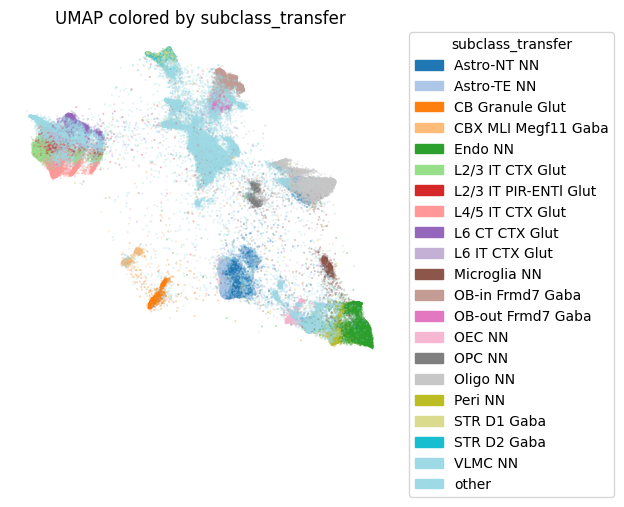

In [109]:
import matplotlib.pyplot as plt                                                                                                                                                                           
import matplotlib.patches as mpatches  
from matplotlib.colors import Normalize                                                                                                                                                                   
                                                                                                                                                                                                        
metadata_feature = "subclass_transfer"                                                                                                                                                        
                                                        
colors = metadata[metadata_feature].iloc[subset_indices]        

# only top category are plotted
top_cats = colors.value_counts().nlargest(20).index                                                                                                                                                       
colors = colors.where(colors.isin(top_cats), other="other")

categories = colors.astype('category')                    
category_codes = categories.cat.codes
unique_cats = categories.cat.categories                                                                                                                                                                   

cmap = plt.get_cmap('tab20')                                                                                                                                                                               
norm = Normalize(vmin=0, vmax=len(unique_cats) - 1)       

scatter = plt.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],                                                                                                                                         
                    c=category_codes, alpha=0.5, s=0.1, cmap=cmap, norm=norm)
                                                                                                                                                                                                        
patches = [mpatches.Patch(color=cmap(norm(i)), label=cat)                                                                                                                                                 
         for i, cat in enumerate(unique_cats)]
plt.legend(handles=patches, markerscale=5, title=metadata_feature,                                                                                                                                        
         bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.axis('off')                                                                                                                                                                                           
plt.title(f"UMAP colored by {metadata_feature}")
plt.tight_layout()                                                                                                                                                                                        
plt.show() 

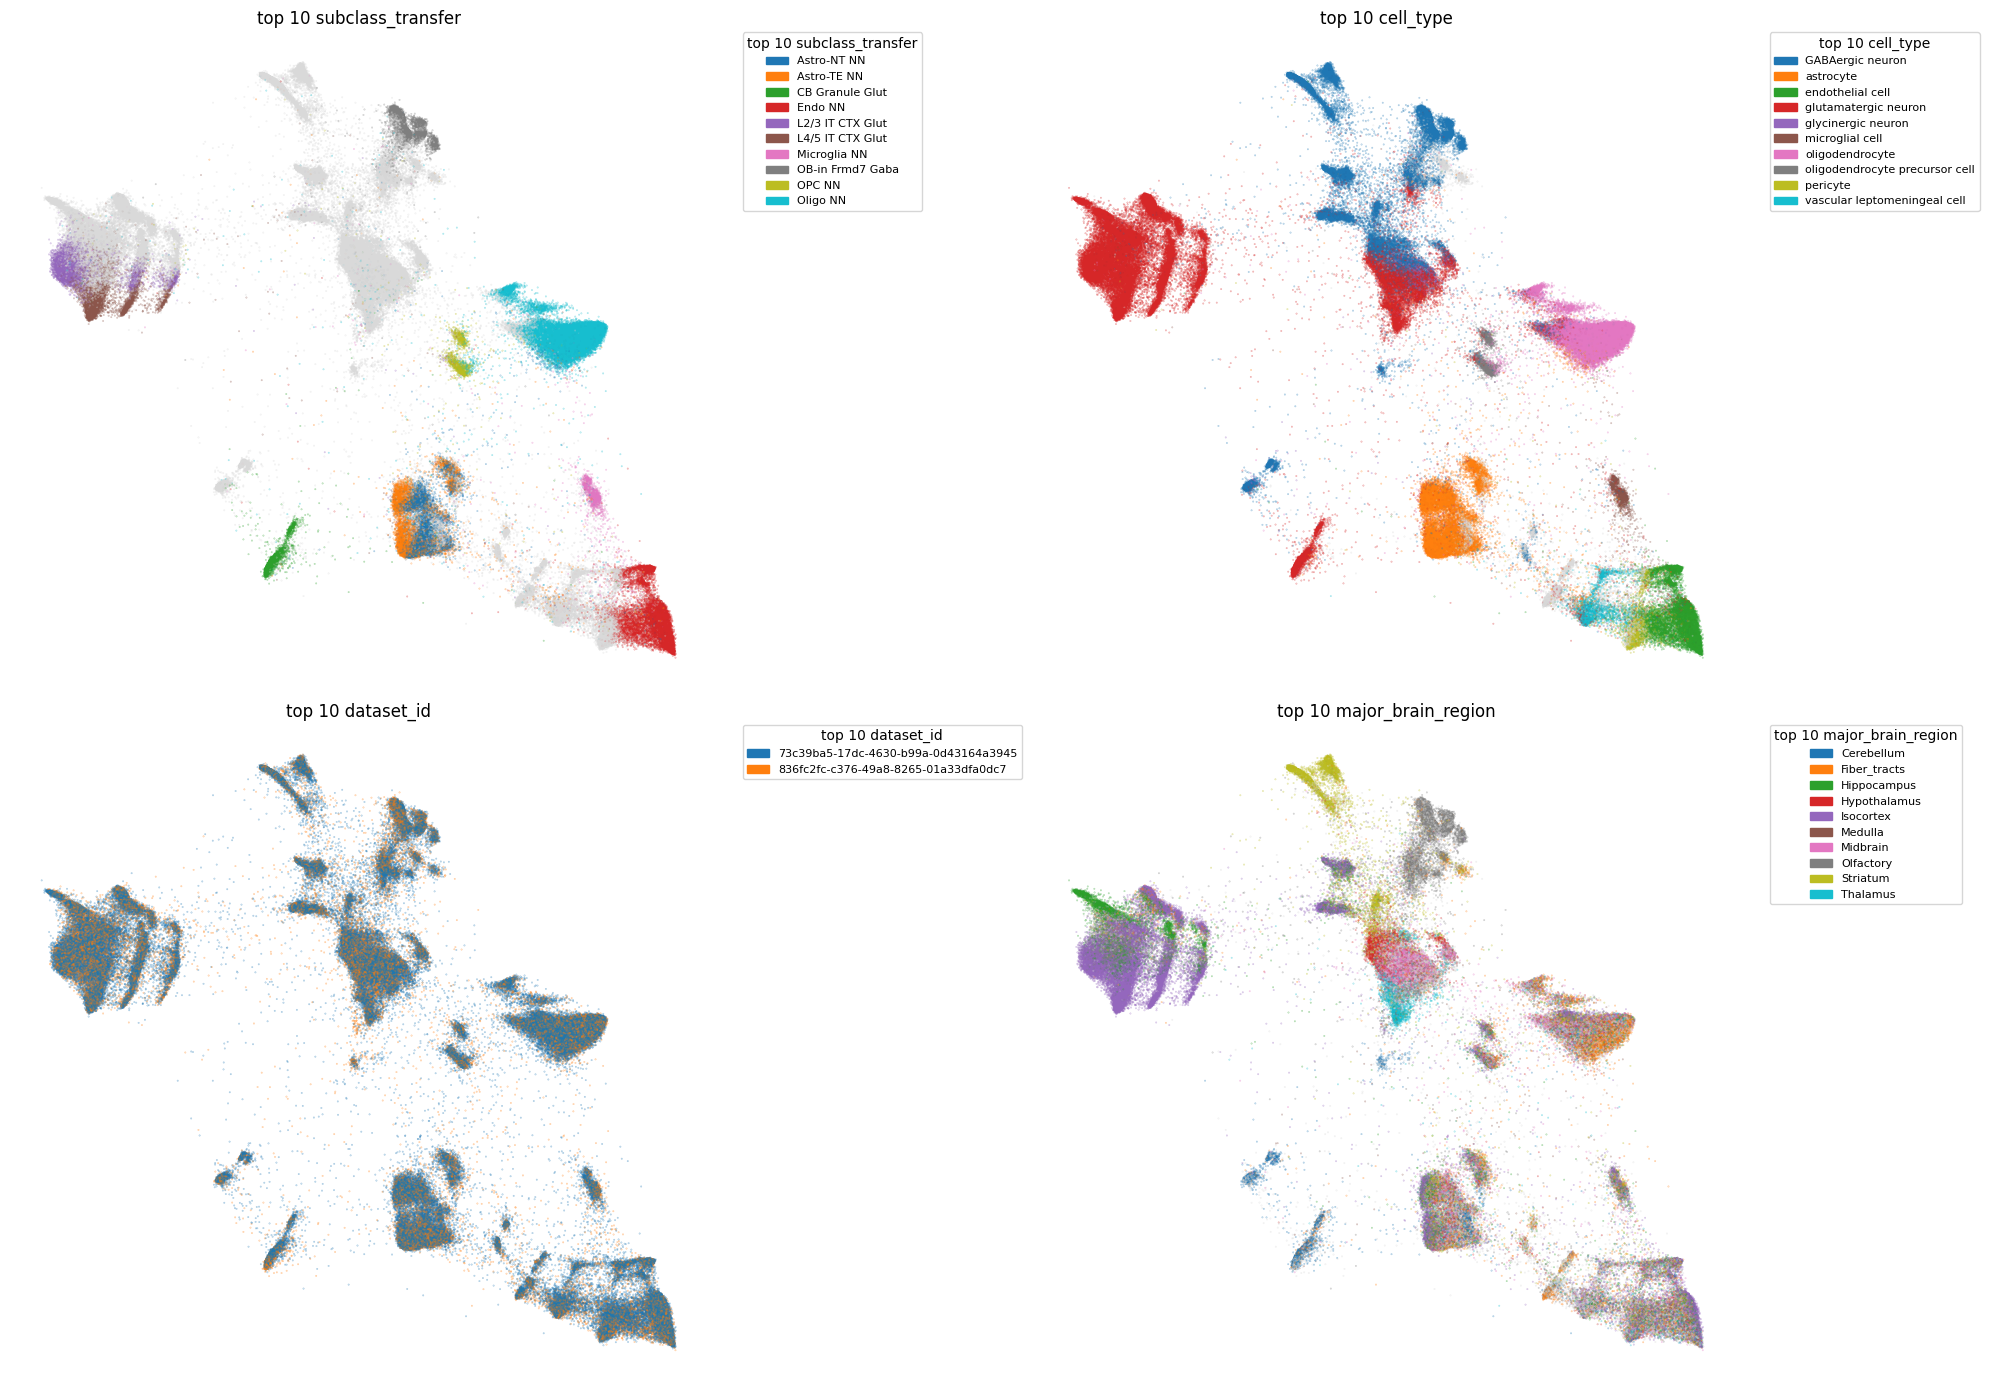

In [110]:
import matplotlib.pyplot as plt                                                                                                                                                                           
import matplotlib.patches as mpatches  
                                                                                                                                                                                                        
features = ["subclass_transfer", "cell_type","dataset_id","major_brain_region"]                                                                                                                                                   
top_n = 10                                                                                                                                                                                                
                                                    
fig, axes = plt.subplots(2, 2, figsize=(20, 14))                                                                                                                                                          
axes = axes.flatten()                                                                                                                                                           

for ax, metadata_feature in zip(axes, features):                                                                                                                                                          
  colors = metadata[metadata_feature].iloc[subset_indices]
  top_cats = colors.value_counts().nlargest(top_n).index
  labels = colors.where(colors.isin(top_cats), other="other")                                                                                                                                           
  unique_cats = [c for c in labels.astype('category').cat.categories if c != "other"]
                                                                                                                                                                                                        
  cmap = plt.get_cmap('tab10')                          
  color_map = {cat: cmap(i / top_n) for i, cat in enumerate(unique_cats)}                                                                                                                               
  color_map["other"] = (0.85, 0.85, 0.85, 0.3)          
  point_colors = labels.map(color_map)                                                                                                                                                                  

  ax.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],                                                                                                                                                
             c=point_colors, alpha=0.5, s=0.1)          
                                                                                                                                                                                                        
  patches = [mpatches.Patch(color=color_map[cat], label=cat) for cat in unique_cats]
  ax.legend(handles=patches, markerscale=5, title=f"top {top_n} {metadata_feature}",                                                                                                                    
            bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0, fontsize=8)                                                                                                                    
  ax.axis('off')
  ax.set_title(f"top {top_n} {metadata_feature}")                                                                                                                                                       
                                                                                                                                                                                                        
plt.tight_layout()
plt.show()   

## Save UMAP

In [111]:
n_samples = data_tensor.shape[0]
embedding_dim = 2  # since n_components=2
X_umap_pytorch = np.zeros((n_samples, embedding_dim), dtype=np.float32)

# --- Batch transform ---
print("Starting batch transformation ...", flush=True)
batch_size = 1_000_000
for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)
    batch = data_tensor[start:end]
    emb = pumap.transform(batch)
    X_umap_pytorch[start:end] = emb
    print(f"Processed {end}/{n_samples}", flush=True)

Starting batch transformation ...
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 1000000/5788737
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 2000000/5788737
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 3000000/5788737
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 4000000/5788737
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 5000000/5788737
Reducing array of shape torch.Size([788737, 50]) to (788737, 2)
Processed 5788737/5788737


In [112]:
config = {}
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
config["pumap_model_file"] = model_path
config["pca_model_file"]= os.path.join(results_dir,"ipca_model.pkl") # hard-coded for ipca transformation
config["knn_k"] = 30
config["knn_nprobe"] = 20
config["pca_n_components"] =50

# --- Axis adjustment ---
UMAP1_size = np.ptp(X_umap_pytorch[:, 0])
UMAP2_size = np.ptp(X_umap_pytorch[:, 1])
if UMAP1_size < UMAP2_size:
    print("Swapping axes (too tall UMAP)...", flush=True)
    X_umap_pytorch[:, [0, 1]] = X_umap_pytorch[:, [1, 0]]
    config["swap_xy_matrix"] =  [
        [0, 1],
        [1, 0]
    ]
else:
    config["swap_xy_matrix"] =  [
        [1, 0],
        [0, 1]
    ]
config["PUMAP_k"]=k
config

{'pumap_model_file': '/mnt/efsUCE/Zhuang-ABCA-1-2_cxg_shuffled/pytorch_e35.pkl',
 'pca_model_file': '/mnt/efsUCE/Zhuang-ABCA-1-2_cxg_shuffled/ipca_model.pkl',
 'knn_k': 30,
 'knn_nprobe': 20,
 'pca_n_components': 50,
 'swap_xy_matrix': [[1, 0], [0, 1]],
 'PUMAP_k': 10}

In [113]:
# --- Saveing transformation config ----
config_path = os.path.join(results_dir, f"transform_e{existing_model_iteration}.json")
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

In [114]:
# --- Save umap ----
umap_file = f"umap_e{existing_model_iteration}.npy"
output_path = os.path.join(results_dir, umap_file)
np.save(output_path, X_umap_pytorch)